In [ ]:
from google.colab import files

# Run this cell to prompt an upload button
uploaded = files.upload()

Saving Project_1_Raw_Retail_Sales_Data.csv to Project_1_Raw_Retail_Sales_Data.csv


In [ ]:

import pandas as pd

df = pd.read_csv('/content/Project_1_Raw_Retail_Sales_Data.csv')

print(df.head())


         Date Region         Product     Category  Units_Sold  Unit_Price_INR  \
0  2026-01-03  North  Wireless Mouse  Accessories          12             650   
1  2026-01-05  South  Wireless Mouse  Accessories          18             650   
2  2026-01-08   East  Wireless Mouse  Accessories          10             650   
3  2026-01-10   West  Wireless Mouse  Accessories          16             650   
4  2026-01-12  North        Keyboard  Accessories           9            1200   

   Unit_Cost_INR  Discount_Rate  
0            390           0.05  
1            390           0.10  
2            390           0.00  
3            390           0.15  
4            720           0.05  


In [ ]:

print("Dataset size:")
print(df.shape)

print("\nColumn names:")
print(df.columns)

print("\nDataset information:")
df.info()


Dataset size:
(60, 8)

Column names:
Index(['Date', 'Region', 'Product', 'Category', 'Units_Sold', 'Unit_Price_INR',
       'Unit_Cost_INR', 'Discount_Rate'],
      dtype='object')

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Date            60 non-null     object 
 1   Region          60 non-null     object 
 2   Product         60 non-null     object 
 3   Category        60 non-null     object 
 4   Units_Sold      60 non-null     int64  
 5   Unit_Price_INR  60 non-null     int64  
 6   Unit_Cost_INR   60 non-null     int64  
 7   Discount_Rate   60 non-null     float64
dtypes: float64(1), int64(3), object(4)
memory usage: 3.9+ KB


In [ ]:

print("Missing values in each column:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nSummary of numerical columns:")
print(df.describe())


Missing values in each column:
Date              0
Region            0
Product           0
Category          0
Units_Sold        0
Unit_Price_INR    0
Unit_Cost_INR     0
Discount_Rate     0
dtype: int64

Duplicate rows:
0

Summary of numerical columns:
       Units_Sold  Unit_Price_INR  Unit_Cost_INR  Discount_Rate
count   60.000000       60.000000      60.000000      60.000000
mean    16.650000     1116.666667     670.000000       0.209167
std      6.419845      354.948870     212.969322       0.111800
min      7.000000      650.000000     390.000000       0.000000
25%     12.000000      650.000000     390.000000       0.137500
50%     15.000000     1200.000000     720.000000       0.200000
75%     20.000000     1500.000000     900.000000       0.300000
max     34.000000     1500.000000     900.000000       0.450000


In [ ]:

# Calculate sales revenue after discounts
df["Revenue"] = (
    df["Units_Sold"]
    * df["Unit_Price_INR"]
    * (1 - df["Discount_Rate"])
)

# Calculate total direct product cost
df["COGS"] = df["Units_Sold"] * df["Unit_Cost_INR"]

# Calculate gross profit
df["Gross_Profit"] = df["Revenue"] - df["COGS"]

# Calculate gross profit margin as a percentage
df["Gross_Profit_Margin"] = (
    df["Gross_Profit"] / df["Revenue"] * 100
)

# Display the first five records with our new calculations
print(df[[
    "Product",
    "Units_Sold",
    "Revenue",
    "COGS",
    "Gross_Profit",
    "Gross_Profit_Margin"
]].head())


          Product  Units_Sold  Revenue  COGS  Gross_Profit  \
0  Wireless Mouse          12   7410.0  4680        2730.0   
1  Wireless Mouse          18  10530.0  7020        3510.0   
2  Wireless Mouse          10   6500.0  3900        2600.0   
3  Wireless Mouse          16   8840.0  6240        2600.0   
4        Keyboard           9  10260.0  6480        3780.0   

   Gross_Profit_Margin  
0            36.842105  
1            33.333333  
2            40.000000  
3            29.411765  
4            36.842105  


In [ ]:

total_revenue = df["Revenue"].sum()
total_cogs = df["COGS"].sum()
total_gross_profit = df["Gross_Profit"].sum()

overall_margin = (
    total_gross_profit / total_revenue * 100
)

print("Total Revenue: ₹", round(total_revenue, 2))
print("Total COGS: ₹", round(total_cogs, 2))
print("Total Gross Profit: ₹", round(total_gross_profit, 2))
print("Gross Profit Margin:", round(overall_margin, 2), "%")


Total Revenue: ₹ 788747.5
Total COGS: ₹ 613500
Total Gross Profit: ₹ 175247.5
Gross Profit Margin: 22.22 %


In [ ]:

# Compare profitability across products

product_analysis = df.groupby("Product").agg(
    Units_Sold=("Units_Sold", "sum"),
    Revenue=("Revenue", "sum"),
    COGS=("COGS", "sum"),
    Gross_Profit=("Gross_Profit", "sum")
).reset_index()

# Calculate each product's gross profit margin
product_analysis["Gross_Profit_Margin"] = (
    product_analysis["Gross_Profit"]
    / product_analysis["Revenue"] * 100
)

# Show the most profitable product first
product_analysis = product_analysis.sort_values(
    by="Gross_Profit", ascending=False
)

print(product_analysis.round(2).to_string(index=False))


       Product  Units_Sold  Revenue   COGS  Gross_Profit  Gross_Profit_Margin
  Laptop Stand         241 292350.0 216900       75450.0                25.81
      Keyboard         306 283620.0 220320       63300.0                22.32
Wireless Mouse         452 212777.5 176280       36497.5                17.15


In [ ]:

# Compare profitability across regions

region_analysis = df.groupby("Region").agg(
    Units_Sold=("Units_Sold", "sum"),
    Revenue=("Revenue", "sum"),
    COGS=("COGS", "sum"),
    Gross_Profit=("Gross_Profit", "sum")
).reset_index()

# Calculate gross profit margin for each region
region_analysis["Gross_Profit_Margin"] = (
    region_analysis["Gross_Profit"]
    / region_analysis["Revenue"] * 100
)

# Rank regions from highest to lowest gross profit
region_analysis = region_analysis.sort_values(
    by="Gross_Profit", ascending=False
)

print(region_analysis.round(2).to_string(index=False))


Region  Units_Sold  Revenue   COGS  Gross_Profit  Gross_Profit_Margin
  East         208 186987.5 128520       58467.5                31.27
 South         299 236542.5 185070       51472.5                21.76
 North         227 174017.5 134850       39167.5                22.51
  West         265 191200.0 165060       26140.0                13.67


In [ ]:

# Create discount groups for comparison

df["Discount_Group"] = df["Discount_Rate"].apply(
    lambda x: f"{x:.0%}"
)

# Compare performance at different discount rates
discount_analysis = df.groupby("Discount_Group").agg(
    Number_of_Records=("Revenue", "count"),
    Units_Sold=("Units_Sold", "sum"),
    Revenue=("Revenue", "sum"),
    Gross_Profit=("Gross_Profit", "sum")
).reset_index()

# Calculate overall margin within each discount group
discount_analysis["Gross_Profit_Margin"] = (
    discount_analysis["Gross_Profit"]
    / discount_analysis["Revenue"] * 100
)

print(discount_analysis.round(2).to_string(index=False))


Discount_Group  Number_of_Records  Units_Sold  Revenue  Gross_Profit  Gross_Profit_Margin
            0%                  3          28  30200.0       12080.0                40.00
           10%                  7          91  90045.0       30015.0                33.33
           15%                  8         106 103232.5       30362.5                29.41
           20%                 10         151 138480.0       34620.0                25.00
           25%                  9         162 126412.5       25282.5                20.00
           30%                  8         155 107205.0       15315.0                14.29
           35%                  6         142  84045.0        6465.0                 7.69
           40%                  3          82  38910.0           0.0                 0.00
           45%                  1          29  10367.5        -942.5                -9.09
            5%                  5          53  59850.0       22050.0                36.84


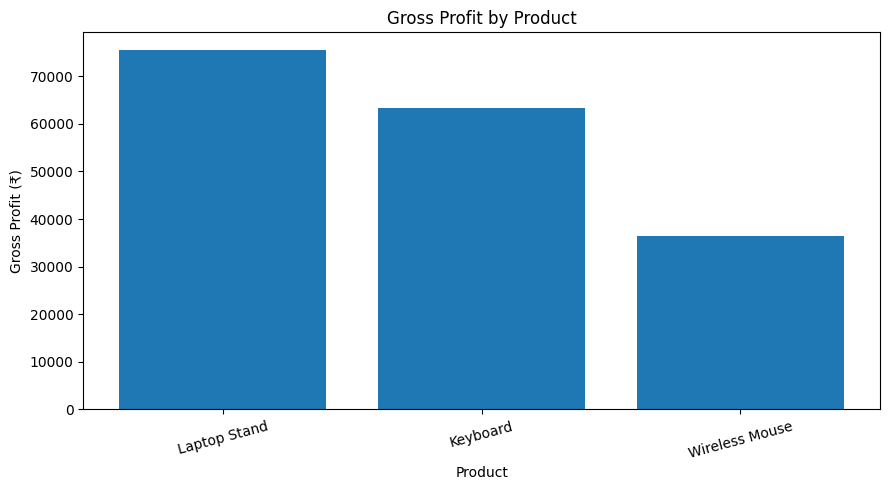

In [ ]:

import matplotlib.pyplot as plt

# Create a bar chart of gross profit by product
plt.figure(figsize=(9, 5))

plt.bar(
    product_analysis["Product"],
    product_analysis["Gross_Profit"]
)

plt.title("Gross Profit by Product")
plt.xlabel("Product")
plt.ylabel("Gross Profit (₹)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


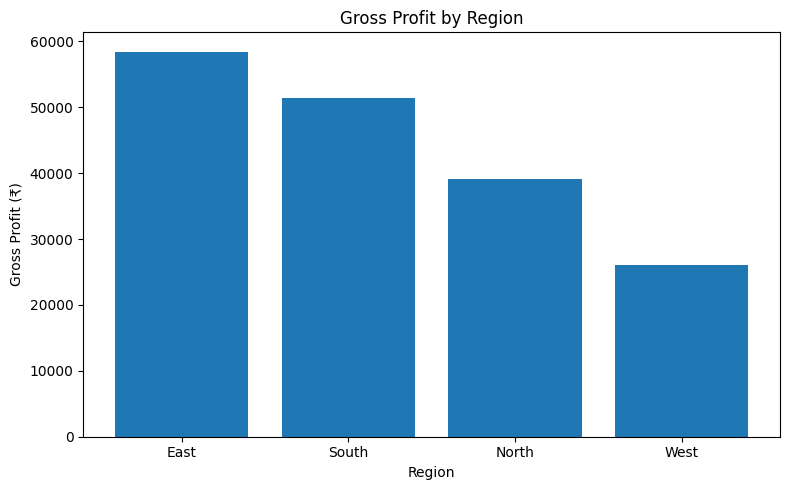

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    region_analysis["Region"],
    region_analysis["Gross_Profit"]
)

plt.title("Gross Profit by Region")
plt.xlabel("Region")
plt.ylabel("Gross Profit (₹)")
plt.tight_layout()
plt.show()


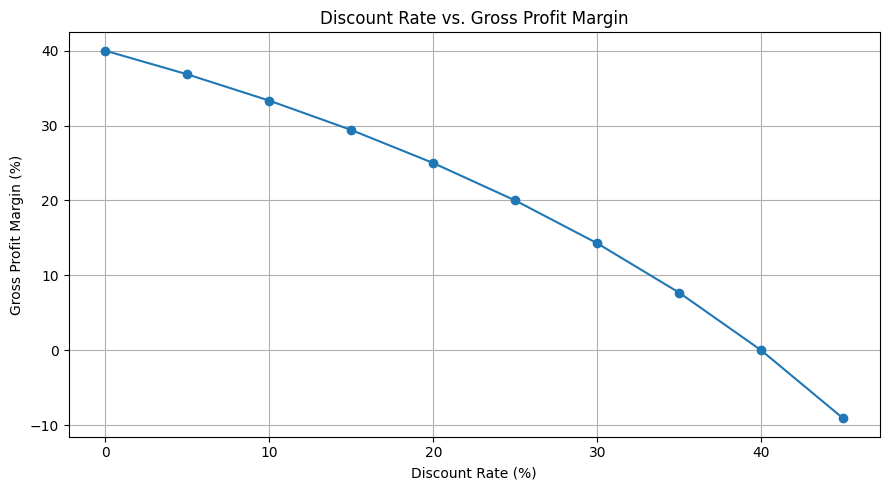

In [ ]:

# Sort discount groups numerically before plotting
discount_plot = discount_analysis.copy()

discount_plot["Discount_Numeric"] = (
    discount_plot["Discount_Group"].str.replace("%", "").astype(float)
)

discount_plot = discount_plot.sort_values("Discount_Numeric")

plt.figure(figsize=(9, 5))

plt.plot(
    discount_plot["Discount_Numeric"],
    discount_plot["Gross_Profit_Margin"],
    marker="o"
)

plt.title("Discount Rate vs. Gross Profit Margin")
plt.xlabel("Discount Rate (%)")
plt.ylabel("Gross Profit Margin (%)")
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:

# Save the three summary tables as CSV files

product_analysis.to_csv(
    "product_profitability_analysis.csv",
    index=False
)

region_analysis.to_csv(
    "regional_profitability_analysis.csv",
    index=False
)

discount_analysis.to_csv(
    "discount_profitability_analysis.csv",
    index=False
)

print("All three analysis files have been saved.")


All three analysis files have been saved.


In [ ]:

from google.colab import files

files.download("product_profitability_analysis.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>